In [1]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.3
NumPy version: 2.4.6


In [2]:
from pathlib import Path

file_path = (
    Path("..")
    / "data"
    / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [4]:
print("Data Types:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts(dropna=False))

Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    

In [5]:
# 1. Check column data types
print("DATA TYPES")
display(df.dtypes)

# 2. Check missing values
print("\nMISSING VALUES")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Count")
)

# 3. Check blank or whitespace-only values
print("\nBLANK VALUES")
blank_counts = df.select_dtypes(include="object").apply(
    lambda col: col.astype("string").str.strip().eq("").sum()
)
display(blank_counts[blank_counts > 0])

# 4. Check duplicate customer IDs
print("\nDUPLICATE CUSTOMER IDs")
print("Total duplicate IDs:", df["customerID"].duplicated().sum())

# 5. Check churn values
print("\nCHURN VALUES")
display(df["Churn"].value_counts(dropna=False))

DATA TYPES


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


MISSING VALUES


,Missing_Count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



BLANK VALUES


C:\Users\MY PC\AppData\Local\Temp\ipykernel_13796\2675755627.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  blank_counts = df.select_dtypes(include="object").apply(


TotalCharges    11
dtype: int64


DUPLICATE CUSTOMER IDs
Total duplicate IDs: 0

CHURN VALUES


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
# Identify blank TotalCharges records
blank_mask = (
    df["TotalCharges"]
    .astype("string")
    .str.strip()
    .eq("")
)

blank_records = df.loc[
    blank_mask,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

print("Number of blank records:", len(blank_records))

display(blank_records)

Number of blank records: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [7]:
total_charges_test = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("Original blank values:", blank_mask.sum())
print("Numeric conversion missing values:", total_charges_test.isna().sum())

print("\nConverted data type:")
print(total_charges_test.dtype)

print("\nSample converted values:")
display(total_charges_test.head(10))

Original blank values: 11
Numeric conversion missing values: 11

Converted data type:
float64

Sample converted values:


0      29.85
1    1889.50
2     108.15
3    1840.75
4     151.65
5     820.50
6    1949.40
7     301.90
8    3046.05
9    3487.95
Name: TotalCharges, dtype: float64

In [8]:
# Create a separate cleaned dataset
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].str.strip(),
    errors="coerce"
)

# Fill blank TotalCharges for zero-tenure customers
mask = (
    df_clean["tenure"].eq(0)
    & df_clean["TotalCharges"].isna()
)

df_clean.loc[mask, "TotalCharges"] = 0

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicate customer IDs:",
      df_clean["customerID"].duplicated().sum())
print("TotalCharges type:", df_clean["TotalCharges"].dtype)

Original rows: 7043
Cleaned rows: 7043
Missing values: 0
Duplicate customer IDs: 0
TotalCharges type: float64


In [9]:
print("Churn Distribution:")
display(df_clean["Churn"].value_counts())

print("\nZero-tenure customers:")
print(df_clean["tenure"].eq(0).sum())

print("\nTotalCharges for zero-tenure customers:")
display(
    df_clean.loc[
        df_clean["tenure"].eq(0),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Churn Distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Zero-tenure customers:
11

TotalCharges for zero-tenure customers:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No


In [10]:
# Overall Customer Churn Analysis

total_customers = len(df_clean)

churned_customers = (df_clean["Churn"] == "Yes").sum()

retained_customers = (df_clean["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

print("CUSTOMER CHURN ANALYSIS")
print("-" * 35)

print(f"Total Customers: {total_customers}")
print(f"Churned Customers: {churned_customers}")
print(f"Retained Customers: {retained_customers}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

CUSTOMER CHURN ANALYSIS
-----------------------------------
Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54%
Retention Rate: 73.46%


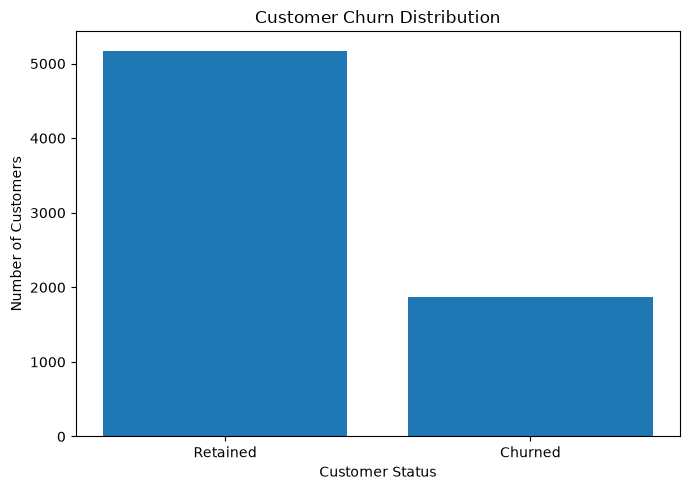

In [11]:
import matplotlib.pyplot as plt

churn_counts = df_clean["Churn"].value_counts().reindex(
    ["No", "Yes"]
)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Retained", "Churned"],
    churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [12]:
# Contract-wise churn analysis

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

contract_churn["Total_Customers"] = (
    contract_churn["No"] + contract_churn["Yes"]
)

contract_churn["Churn_Rate_%"] = (
    contract_churn["Yes"]
    / contract_churn["Total_Customers"]
    * 100
)

contract_churn = contract_churn.sort_values(
    "Churn_Rate_%",
    ascending=False
)

display(contract_churn.round(2))

Churn,No,Yes,Total_Customers,Churn_Rate_%
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83


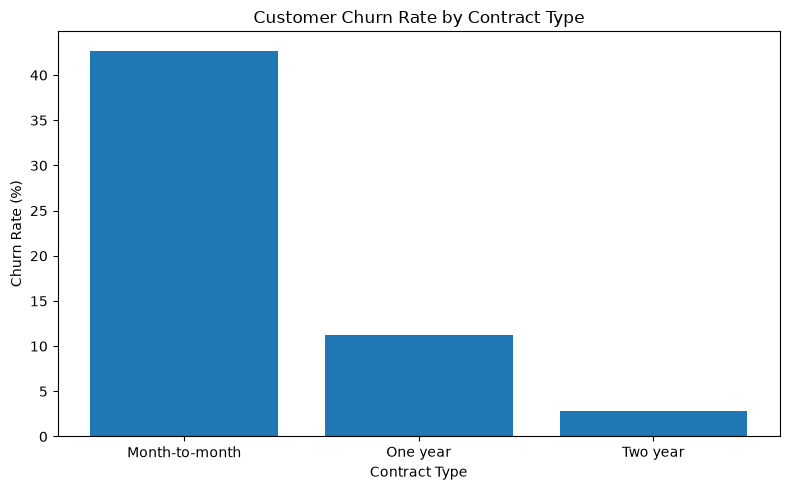

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    contract_churn.index,
    contract_churn["Churn_Rate_%"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [14]:
# Create customer tenure groups

df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 60, float("inf")],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-60 Months",
        "60+ Months"
    ]
)

# Calculate churn rate for each tenure group

tenure_churn = pd.crosstab(
    df_clean["TenureGroup"],
    df_clean["Churn"]
)

tenure_churn["Total_Customers"] = (
    tenure_churn["No"] + tenure_churn["Yes"]
)

tenure_churn["Churn_Rate_%"] = (
    tenure_churn["Yes"]
    / tenure_churn["Total_Customers"]
    * 100
)

display(tenure_churn.round(2))

Churn,No,Yes,Total_Customers,Churn_Rate_%
TenureGroup,,,,
0-12 Months,1149,1037,2186,47.44
13-24 Months,730,294,1024,28.71
25-48 Months,1269,325,1594,20.39
49-60 Months,712,120,832,14.42
60+ Months,1314,93,1407,6.61


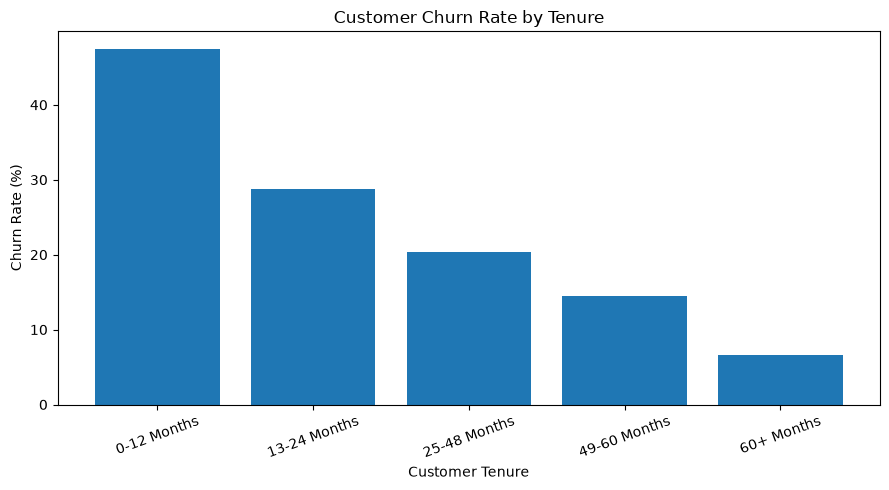

In [15]:
plt.figure(figsize=(9, 5))

plt.bar(
    tenure_churn.index.astype(str),
    tenure_churn["Churn_Rate_%"]
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [16]:
# Create monthly charge groups

df_clean["MonthlyChargeGroup"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=[0, 35, 70, 100, float("inf")],
    labels=[
        "Low (0-35)",
        "Medium (35-70)",
        "High (70-100)",
        "Very High (100+)"
    ],
    include_lowest=True
)

# Analyze churn by monthly charges

charges_churn = pd.crosstab(
    df_clean["MonthlyChargeGroup"],
    df_clean["Churn"]
)

charges_churn["Total_Customers"] = (
    charges_churn["No"] + charges_churn["Yes"]
)

charges_churn["Churn_Rate_%"] = (
    charges_churn["Yes"]
    / charges_churn["Total_Customers"]
    * 100
)

display(charges_churn.round(2))

Churn,No,Yes,Total_Customers,Churn_Rate_%
MonthlyChargeGroup,,,,
Low (0-35),1546,189,1735,10.89
Medium (35-70),1312,413,1725,23.94
High (70-100),1667,1014,2681,37.82
Very High (100+),649,253,902,28.05


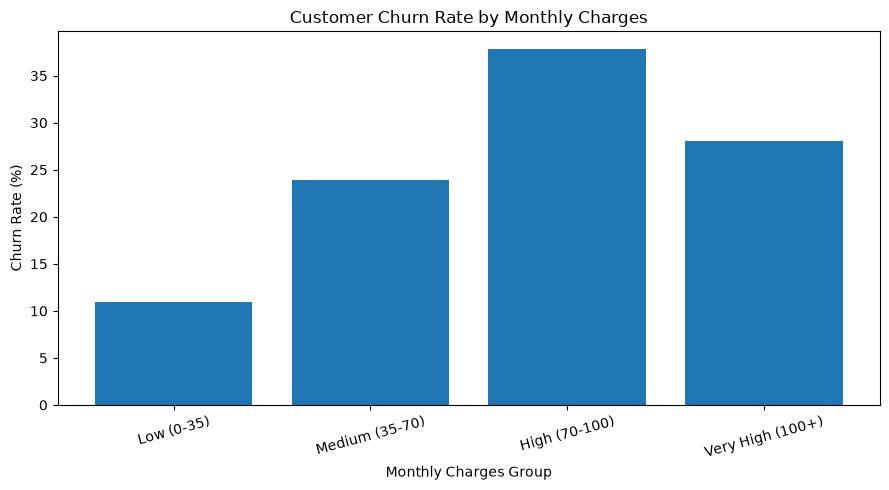

In [17]:
plt.figure(figsize=(9, 5))

plt.bar(
    charges_churn.index.astype(str),
    charges_churn["Churn_Rate_%"]
)

plt.title("Customer Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [18]:
# Churn analysis by Internet Service

internet_churn = pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"]
)

internet_churn["Total_Customers"] = (
    internet_churn["No"] + internet_churn["Yes"]
)

internet_churn["Churn_Rate_%"] = (
    internet_churn["Yes"]
    / internet_churn["Total_Customers"]
    * 100
)

display(internet_churn.round(2))

Churn,No,Yes,Total_Customers,Churn_Rate_%
InternetService,,,,
DSL,1962,459,2421,18.96
Fiber optic,1799,1297,3096,41.89
No,1413,113,1526,7.40


In [19]:
payment_churn = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"]
)

payment_churn["Total_Customers"] = (
    payment_churn["No"] + payment_churn["Yes"]
)

payment_churn["Churn_Rate_%"] = (
    payment_churn["Yes"]
    / payment_churn["Total_Customers"]
    * 100
)

payment_churn = payment_churn.sort_values(
    "Churn_Rate_%",
    ascending=False
)

display(payment_churn.round(2))

Churn,No,Yes,Total_Customers,Churn_Rate_%
PaymentMethod,,,,
Electronic check,1294,1071,2365,45.29
Mailed check,1304,308,1612,19.11
Bank transfer (automatic),1286,258,1544,16.71
Credit card (automatic),1290,232,1522,15.24


In [20]:
# Compare churned and retained customers

customer_summary = df_clean.groupby("Churn").agg(
    Total_Customers=("customerID", "count"),
    Average_Tenure=("tenure", "mean"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Average_Total_Charges=("TotalCharges", "mean")
)

display(customer_summary.round(2))

,Total_Customers,Average_Tenure,Average_Monthly_Charges,Average_Total_Charges
Churn,,,,
No,5174,37.57,61.27,2549.91
Yes,1869,17.98,74.44,1531.80


In [21]:
# Sort contract types by churn rate

display(
    contract_churn[
        ["No", "Yes", "Total_Customers", "Churn_Rate_%"]
    ].round(2)
)

Churn,No,Yes,Total_Customers,Churn_Rate_%
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83
